# สรุปผลการทดลอง thai-flyvec

ตอบคำถามวิจัย 3 ข้อจากผลใน `results/` ที่ได้จาก

```bash
python scripts/run_experiments.py
python scripts/summarize_results.py
```

ทุกค่าเป็นค่าเฉลี่ย ± ส่วนเบี่ยงเบนมาตรฐานของ 3 seed (docs/decisions.md D9)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from thai_flyvec import report

raw, resources = report.load(ROOT / "results")
W = 11  # window length of the main table (default of the original paper)
pd.read_json(ROOT / "results" / "machine.json", typ="series")

platform     Linux-6.18.44-fc-v233-x86_64-with-glibc2.39
processor           Intel(R) Xeon(R) Processor @ 2.10GHz
cpu_count                                              4
python                                           3.13.18
numpy                                              2.5.3
gensim                                             4.4.0
memory_gb                                           15.7
dtype: object

## RQ1 FlyVec ได้คะแนนความคล้ายคลึงของคำใกล้ word2vec และ fastText แค่ไหน

ρ คำนวณบนคู่คำที่ทุกโมเดลรู้จัก (D7) แถว fastText + subword OOV แสดงผลบนคู่คำชุดเดียวกัน ส่วนตาราง OOV ด้านล่างแสดงว่า subword ช่วยลดคู่คำ OOV ได้เท่าไร

In [2]:
report.summary_table(raw, w=W)

,model,k,TH-WordSim-353 ρ,TH-SimLex-999 ρ,wisesight accuracy,wisesight macro-F1
0,FlyVec,4,0.395 ± 0.068,0.289 ± 0.022,0.600 ± 0.009,0.396 ± 0.004
1,FlyVec,8,0.385 ± 0.039,0.329 ± 0.027,0.616 ± 0.006,0.405 ± 0.007
2,FlyVec,16,0.363 ± 0.050,0.331 ± 0.032,0.619 ± 0.001,0.418 ± 0.006
3,FlyVec,32,0.367 ± 0.051,0.347 ± 0.030,0.620 ± 0.011,0.419 ± 0.013
4,FlyVec,64,0.346 ± 0.045,0.350 ± 0.027,0.619 ± 0.006,0.422 ± 0.011
5,word2vec binary,4,0.219 ± 0.076,0.302 ± 0.020,0.604 ± 0.008,0.397 ± 0.007
6,word2vec binary,8,0.303 ± 0.086,0.370 ± 0.017,0.609 ± 0.008,0.411 ± 0.009
7,word2vec binary,16,0.369 ± 0.065,0.425 ± 0.034,0.621 ± 0.009,0.418 ± 0.015
8,word2vec binary,32,0.447 ± 0.013,0.454 ± 0.020,0.617 ± 0.002,0.407 ± 0.011
9,word2vec binary,64,0.531 ± 0.036,0.484 ± 0.025,0.625 ± 0.005,0.425 ± 0.014


In [3]:
report.oov_table(raw)

model,fasttext_subword,word2vec
task,,
th-simlex-999,0.0,0.256256
th-wordsim-353,0.0,0.399433


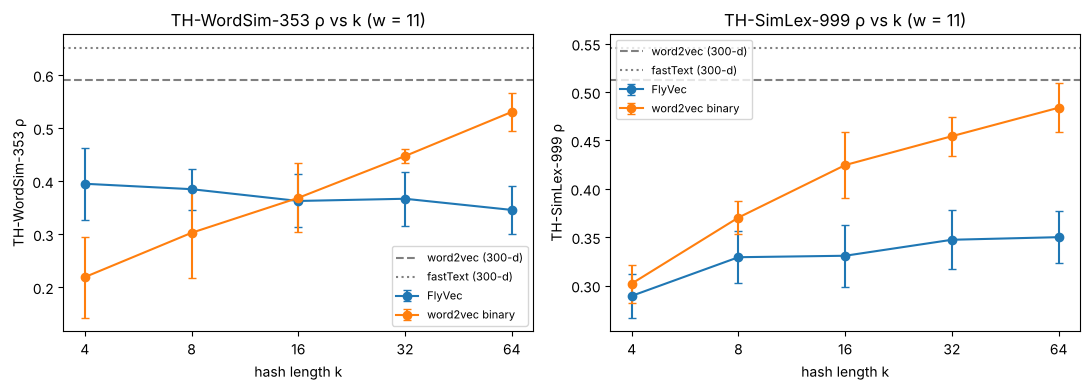

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, score in zip(axes, ["TH-WordSim-353 ρ", "TH-SimLex-999 ρ"]):
    report.plot_vs_k(raw, score, w=W, ax=ax)
fig.tight_layout()

## RQ2 จำแนกความรู้สึกแล้วความแม่นยำลดลงเท่าไร เทียบกับหน่วยความจำและเวลาเทรนที่ประหยัดได้

ขนาดของโมเดลไบนารีคือขนาดของ code 0/1 ของคำทั้งคลังศัพท์ (1 บิตต่อเซลล์/มิติ) ขนาดไฟล์ที่เทรนได้จริงอยู่ในตาราง resources

In [5]:
report.resource_table(resources, w=W)

,train_minutes,size_mb,codes_mb
model,,,
fasttext,4.406968,252.531408,NaN
flyvec,56.490159,61.036652,0.953674
word2vec,2.373431,23.649217,0.715256


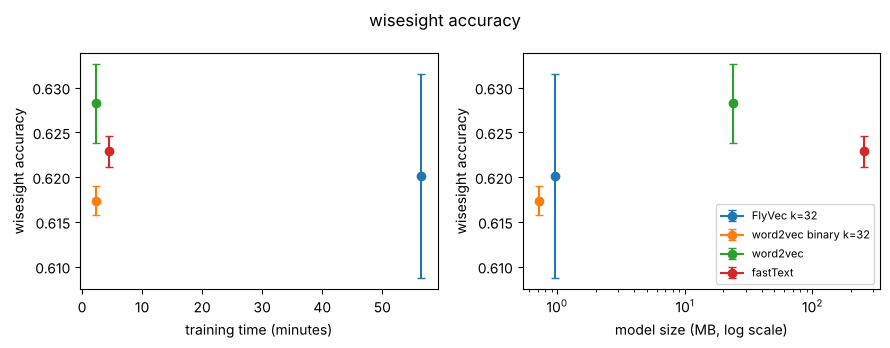

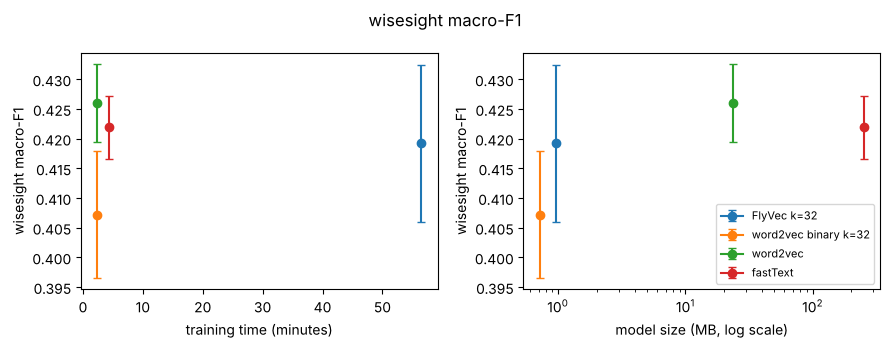

In [6]:
for score in ["wisesight accuracy", "wisesight macro-F1"]:
    axes = report.plot_vs_resources(raw, resources, score, k=32, w=W)
    axes[0].figure.suptitle(score)
    axes[0].figure.tight_layout()

## RQ3 ความยาว hash (k) เท่าไรเหมาะกับภาษาไทย

In [7]:
pd.concat([report.best_k(raw, score) for score in report.SCORES.values()])

,model,w,k,mean,score
0,flyvec,5,16,0.388018,TH-WordSim-353 ρ
1,flyvec,11,4,0.395086,TH-WordSim-353 ρ
2,flyvec,15,8,0.419691,TH-WordSim-353 ρ
3,word2vec_binary,5,64,0.467229,TH-WordSim-353 ρ
4,word2vec_binary,11,64,0.530517,TH-WordSim-353 ρ
5,word2vec_binary,15,64,0.523913,TH-WordSim-353 ρ
0,flyvec,5,64,0.407082,TH-SimLex-999 ρ
1,flyvec,11,64,0.350027,TH-SimLex-999 ρ
2,flyvec,15,64,0.343839,TH-SimLex-999 ρ
3,word2vec_binary,5,64,0.431306,TH-SimLex-999 ρ


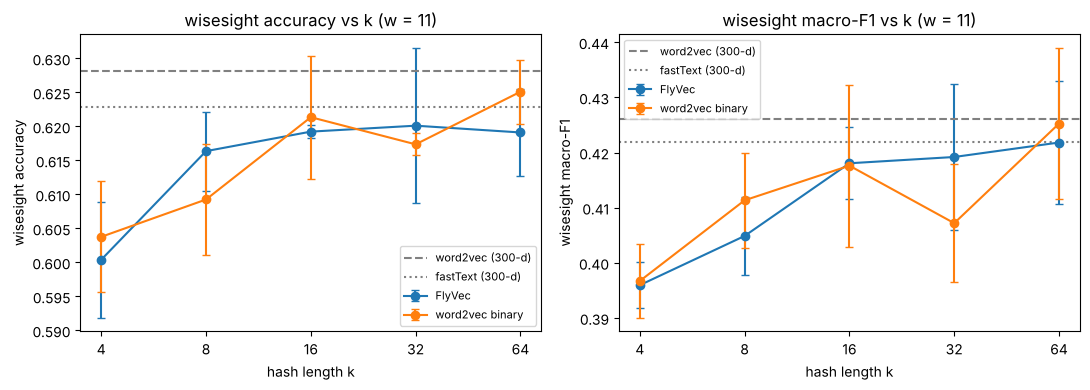

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, score in zip(axes, ["wisesight accuracy", "wisesight macro-F1"]):
    report.plot_vs_k(raw, score, w=W, ax=ax)
fig.tight_layout()

## ผลของขนาดหน้าต่าง w

In [9]:
report.summary_table(raw)

,model,k,w,TH-WordSim-353 ρ,TH-SimLex-999 ρ,wisesight accuracy,wisesight macro-F1
0,FlyVec,4,5,0.322 ± 0.056,0.284 ± 0.017,0.610 ± 0.006,0.401 ± 0.005
1,FlyVec,4,11,0.395 ± 0.068,0.289 ± 0.022,0.600 ± 0.009,0.396 ± 0.004
2,FlyVec,4,15,0.382 ± 0.093,0.274 ± 0.027,0.605 ± 0.012,0.401 ± 0.010
3,FlyVec,8,5,0.369 ± 0.011,0.310 ± 0.020,0.618 ± 0.009,0.424 ± 0.013
4,FlyVec,8,11,0.385 ± 0.039,0.329 ± 0.027,0.616 ± 0.006,0.405 ± 0.007
5,FlyVec,8,15,0.420 ± 0.024,0.306 ± 0.023,0.617 ± 0.003,0.409 ± 0.006
6,FlyVec,16,5,0.388 ± 0.019,0.343 ± 0.017,0.616 ± 0.008,0.420 ± 0.008
7,FlyVec,16,11,0.363 ± 0.050,0.331 ± 0.032,0.619 ± 0.001,0.418 ± 0.006
8,FlyVec,16,15,0.408 ± 0.031,0.311 ± 0.011,0.617 ± 0.004,0.420 ± 0.006
9,FlyVec,32,5,0.372 ± 0.039,0.379 ± 0.003,0.620 ± 0.002,0.422 ± 0.008
